# 03 - Silver Labeling

**IT469 (King Saud University) - NER on Human-Written vs. LLM-Generated News**

## Purpose

This notebook is step 3 of the project pipeline. The LLM-generated News dataset has no entity
annotations, so this project uses **weak supervision**: a NER model fine-tuned on human-annotated
CoNLL-2003 [2] automatically labels every sentence produced by `01_data_preparation.ipynb`. These
automatic labels -- "silver labels" -- become the training and evaluation labels for every later
experiment, in place of the gold labels a human annotator would normally provide.

## Annotator candidates and selection

`02_annotator_selection.ipynb` fine-tuned three candidates on CoNLL-2003 following the RoBERTa [3]
grid-search protocol:

| Candidate | Validation micro F1 | Test micro F1 |
|---|---|---|
| `bert-base-cased` | 0.9531 | 0.9165 |
| `roberta-base` | 0.9615 | 0.9244 |
| `roberta-large` | **0.9699** | 0.9273 |

`roberta-large` has the highest **validation** F1, so it is the annotator used here -- Section 4 below
re-derives this from the saved results rather than hard-coding it, and stops if the configured
`ANNOTATOR_TAG` does not actually have the highest validation F1. Test scores are shown for completeness
only and are never used for the selection (same rule as notebook 02).

## What weak supervision / silver labels mean here

Every word in every sentence gets the annotator's single predicted label (argmax), with **no confidence
filtering and no confidence scores saved** -- plain pseudo-labeling [6], the same setup Ushio et al. [5]
used when a fine-tuned RoBERTa-large labeled unlabeled tweets and models were trained directly on its
predictions, without any human review of the automatic labels. This is a standard, simple weak-supervision
approach (see also Snorkel [7] for a more general framework); its cost is that silver-label quality is
bounded by the annotator's own accuracy, not verified against human judgement on these specific articles.

**Limitation, stated plainly:** silver-label quality on the actual news articles is *not* measured
directly -- there is no human annotation of the news sentences to compare against. It is estimated only
indirectly, by the annotator's own CoNLL-2003 test F1 (0.9273, measured on 1,996 Reuters news
sentences [2]) as a proxy for how good the automatic labels on the (different, topically broader) news
articles are likely to be.

## Protocol (do not change, and do not add steps beyond these)

| Step | Rule | Source / reason |
|---|---|---|
| Annotator selection | Confirm from saved results that `ANNOTATOR_TAG` has the highest validation F1 of the three candidates; select on validation only | Same rule as notebook 02; test scores are displayed but never used for the decision |
| Labels | The annotator's predicted label (argmax) for each word, no confidence filtering, no confidence scores saved | Plain pseudo-labeling [6]; same weak-supervision setup as Ushio et al. [5] |
| Word-level prediction | Tokenize with `is_split_into_words=True` (RoBERTa needs `add_prefix_space=True`), take the prediction at the FIRST subword of each word | Devlin et al. [4]; identical to how the annotator was trained |
| Code check | Before labeling news, run the labeling function on CoNLL-2003 validation and confirm its micro F1 reproduces the annotator's recorded validation F1 (from `best_config.json`) within 0.002 -- stop if not | Verifies the new inference code matches the training setup; a code test only, not a reported result |
| Long sentences | Sentences over 256 subwords (incl. special tokens) are split into consecutive chunks at word boundaries, preferring to cut right after a comma/semicolon/colon in the second half of the chunk, otherwise at the limit. Each chunk is labeled separately and tags concatenated; flag `chunked: true` | The annotator cannot read beyond 256 subwords; notebook 01 found only ~13 long sentences, so the effect is negligible |
| BIO repair | After prediction, any `I-X` not preceded by `B-X` or `I-X` becomes `B-X`. Count repairs per side and split | How `conlleval`/`seqeval` interpret such tags anyway, so entities don't change -- labels just become well-formed BIO [8] |
| Matched training file | `human_train_matched.jsonl` gets its labels by joining on `sent_id` with the labeled full human-train file -- no second labeling run | The matched set is a subset of the full one |

## Entity preservation (what it measures, and its limitation)

For each article pair, using every sentence of that article: `H` = the set of human-side entity strings,
`L` = the set of LLM-side entity strings (entity string = its tokens joined with spaces, lowercased).
**Preservation = |H ∩ L| / |H|** -- the share of the journalist's entity mentions that also appear,
verbatim, in GPT-3.5's version of the same story. Articles with an empty `H` are skipped (and counted).
We also report preservation per entity type: for human entities of type T, the share of their strings
that appear anywhere in `L`.

**Caveat:** this uses exact string matching, so aliases count as different entities ("Biden" vs.
"Joe Biden" vs. "President Biden" are three distinct strings). Preservation as measured here is therefore
a **conservative lower bound** on how much entity content GPT-3.5 actually kept -- true semantic
preservation (accounting for aliases/coreference) is higher.

## What gets saved, and where

Everything lives under the same shared Drive folder as notebooks 01 and 02:
`ROOT = /content/drive/MyDrive/IT469-NER-Project`.

```
ROOT/
├── data/silver/{side}_{split}.jsonl           # input record + ner_tags (BIO-repaired) + chunked
├── data/silver/human_train_matched.jsonl      # labels joined onto the size-matched training subset
├── data/silver/_shards/{side}_{split}/...     # temporary, deleted once each file is complete+verified
├── results/silver/annotator_selection.csv     # all 3 candidates: config, val F1, test F1, selected
├── results/silver/conll_code_check.json       # code-check F1 vs. the recorded validation F1
├── results/silver/labeling_summary.csv        # per side x split: sentences, tokens, chunked, BIO repairs
├── results/silver/entity_counts.csv           # per side x split x entity type: mentions
├── results/silver/entity_stats.csv            # per side x split: entities, entities/100 tokens, % no-entity sentences, distinct strings
├── results/silver/top_entities.csv            # top 20 entity strings per type per side
├── results/silver/entity_preservation_by_article.csv
├── results/silver/entity_preservation_summary.csv
├── results/silver/entity_density.png
├── results/silver/environment.json
├── results/silver/run_log.txt
└── data/_smoke/, results/_smoke/              # smoke-test outputs only
```

## How this feeds the training notebooks

`04_crf_baseline.ipynb` and `05_main_models.ipynb` will train directly on `data/silver/{side}_{split}.jsonl`
and `data/silver/human_train_matched.jsonl` -- the `ner_tags` column produced here *is* the training
signal for every downstream model; nothing about this project's human-vs-LLM comparison can be more
accurate than the silver labels built in this notebook.

## Prerequisites and how to run

1. **GPU runtime required.** Runtime > Change runtime type > T4 GPU.
2. **Drive shortcut.** Same shared `IT469-NER-Project` folder as notebooks 01/02; the notebook stops with
   instructions if `ROOT` is missing.
3. Edit **only** the Configuration cell (Section 1). Leave `SMOKE_TEST = True` for a first run (labels
   ~200 sentences per file plus one synthetic long sentence to exercise chunking).
4. Runtime > Run all. Once it prints "Smoke test passed", set `SMOKE_TEST = False` and Run all again for
   the real run over every sentence.
5. Safe to disconnect and re-run: labeling is resumable at the shard level (`SHARD_SIZE` sentences per
   shard); finished shards and finished files are skipped unless `FORCE_REBUILD = True`.

## References

In-text citations `[1]`-`[10]` point to the numbered list in Section 11 at the end of this notebook.


## 1. Configuration

This is the **only** cell you should edit.


In [1]:
# Configuration: which annotator to use, smoke/rebuild switches, and every labeling constant.

ANNOTATOR_TAG = "roberta-large"   # the candidate selected in notebook 02 (highest validation F1)
SMOKE_TEST = False                  # True = fast pipeline check on a small sample; set False for the real run
FORCE_REBUILD = False              # True = ignore existing outputs and relabel everything from scratch
RUN_CODE_CHECK = True              # True = verify labeling code against the annotator's recorded CoNLL val F1

LABEL_NAMES = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
CANDIDATE_TO_MODEL_ID = {
    "bert-base-cased": "google-bert/bert-base-cased",
    "roberta-base": "FacebookAI/roberta-base",
    "roberta-large": "FacebookAI/roberta-large",
}
assert ANNOTATOR_TAG in CANDIDATE_TO_MODEL_ID, f"ANNOTATOR_TAG must be one of {list(CANDIDATE_TO_MODEL_ID)}"
IS_ROBERTA = "roberta" in ANNOTATOR_TAG  # RoBERTa's tokenizer needs add_prefix_space=True with pre-split tokens

BATCH_SIZE = 64
MAX_LEN = 256               # the annotator's max subword length, including special tokens
SHARD_SIZE = 10000          # sentences per resumable shard when labeling a news file
CODE_CHECK_TOLERANCE = 0.002

SMOKE_N_SENTENCES = 200     # smoke test: sentences labeled per news file (plus one synthetic long sentence)
SMOKE_N_CONLL_VAL = 300     # smoke test: CoNLL validation sentences used for the code check

print("Active configuration")
print("---------------------")
print(f"ANNOTATOR_TAG       : {ANNOTATOR_TAG}")
print(f"IS_ROBERTA           : {IS_ROBERTA}")
print(f"SMOKE_TEST           : {SMOKE_TEST}")
print(f"FORCE_REBUILD        : {FORCE_REBUILD}")
print(f"RUN_CODE_CHECK       : {RUN_CODE_CHECK}")
print(f"BATCH_SIZE           : {BATCH_SIZE}")
print(f"MAX_LEN              : {MAX_LEN}")
print(f"SHARD_SIZE           : {SHARD_SIZE}")
print(f"CODE_CHECK_TOLERANCE : {CODE_CHECK_TOLERANCE}")


Active configuration
---------------------
ANNOTATOR_TAG       : roberta-large
IS_ROBERTA           : True
SMOKE_TEST           : False
FORCE_REBUILD        : False
RUN_CODE_CHECK       : True
BATCH_SIZE           : 64
MAX_LEN              : 256
SHARD_SIZE           : 10000
CODE_CHECK_TOLERANCE : 0.002


## 2. Setup

Install anything missing, import libraries, verify the Transformers API, require a CUDA GPU, and record the environment.


In [2]:
!pip install -q -U pip setuptools wheel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 20.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cu130 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.


In [3]:
# Setup: install only what Colab is missing (do not pin versions -- avoid breaking Colab's preinstalled stack).
import importlib
import subprocess
import sys


def _ensure_installed(import_name, pip_name=None):
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name])


_ensure_installed("seqeval")


In [4]:
# Imports used throughout the notebook.
import gc
import importlib.metadata
import json
import logging
import math
import platform
import shutil
import time
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from datasets import load_from_disk
from seqeval.metrics import f1_score
from transformers import AutoConfig, AutoTokenizer, AutoModelForTokenClassification


In [5]:
# Require a current Transformers API (eval_strategy / processing_class naming, matching notebook 02).
_tf_version_parts = tuple(int(p) for p in transformers.__version__.split(".")[:2])
assert _tf_version_parts >= (4, 46), (
    f"This notebook requires transformers >= 4.46 (found {transformers.__version__}). "
    "Restart the runtime after `pip install -U transformers` if Colab's preinstalled version is older."
)

# Require a CUDA GPU: labeling ~150k sentences in fp16 depends on it.
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected. In Colab: Runtime > Change runtime type > T4 GPU, "
        "then Runtime > Run all again."
    )
device = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)
print(f"GPU detected: {GPU_NAME}")

ENV_INFO = {
    "date_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "seqeval_version": importlib.metadata.version("seqeval"),
    "gpu_name": GPU_NAME,
    "annotator_tag": ANNOTATOR_TAG,
    "smoke_test": SMOKE_TEST,
}
print(json.dumps(ENV_INFO, indent=2))


GPU detected: NVIDIA A100-SXM4-40GB
{
  "date_utc": "2026-10-16T11:46:16.730240+00:00",
  "python_version": "3.13.15",
  "torch_version": "2.11.0+cu130",
  "transformers_version": "5.18.0",
  "seqeval_version": "1.2.2",
  "gpu_name": "NVIDIA A100-SXM4-40GB",
  "annotator_tag": "roberta-large",
  "smoke_test": false
}


## 3. Mount Drive and paths

Mount Google Drive, resolve every path from `ROOT`, create folders, and set up logging that survives disconnects.


In [6]:
# Mount Drive and locate the shared project folder (same ROOT as notebooks 01/02).
from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/IT469-NER-Project")
if not ROOT.exists():
    raise RuntimeError(
        f"{ROOT} does not exist. Add the shared folder as a shortcut in your own My Drive: "
        "Google Drive > Shared with me > IT469-NER-Project > (right-click) Organize > "
        "Add shortcut > My Drive. Then re-run this cell."
    )
print(f"ROOT resolved: {ROOT}")


Mounted at /content/drive
ROOT resolved: /content/drive/MyDrive/IT469-NER-Project


In [7]:
# Resolve every other path from ROOT. Inputs (annotator checkpoints, CoNLL-2003, processed sentences) are
# shared and real regardless of SMOKE_TEST; only THIS notebook's own outputs redirect to _smoke/ paths.
ANNOTATOR_RESULTS_DIR = ROOT / "results" / "annotator"
ANNOTATOR_BEST_DIR = ROOT / "checkpoints" / "annotator" / ANNOTATOR_TAG / "best"
CONLL_DATA_DIR = ROOT / "data" / "raw" / "conll2003"
PROCESSED_DIR = ROOT / "data" / "processed"

SENT_PATHS = {
    ("human", "train"): PROCESSED_DIR / "sentences_human_train.jsonl",
    ("human", "validation"): PROCESSED_DIR / "sentences_human_validation.jsonl",
    ("human", "test"): PROCESSED_DIR / "sentences_human_test.jsonl",
    ("llm", "train"): PROCESSED_DIR / "sentences_llm_train.jsonl",
    ("llm", "validation"): PROCESSED_DIR / "sentences_llm_validation.jsonl",
    ("llm", "test"): PROCESSED_DIR / "sentences_llm_test.jsonl",
}
MATCHED_INPUT_PATH = PROCESSED_DIR / "sentences_human_train_matched.jsonl"

if SMOKE_TEST:
    SILVER_DIR = ROOT / "data" / "_smoke"
    RESULTS_DIR = ROOT / "results" / "_smoke"
else:
    SILVER_DIR = ROOT / "data" / "silver"
    RESULTS_DIR = ROOT / "results" / "silver"

SHARDS_ROOT = SILVER_DIR / "_shards"
MATCHED_OUTPUT_PATH = SILVER_DIR / "human_train_matched.jsonl"

ANNOTATOR_SELECTION_CSV = RESULTS_DIR / "annotator_selection.csv"
CONLL_CODE_CHECK_JSON = RESULTS_DIR / "conll_code_check.json"
LABELING_SUMMARY_CSV = RESULTS_DIR / "labeling_summary.csv"
ENTITY_COUNTS_CSV = RESULTS_DIR / "entity_counts.csv"
ENTITY_STATS_CSV = RESULTS_DIR / "entity_stats.csv"
TOP_ENTITIES_CSV = RESULTS_DIR / "top_entities.csv"
ENTITY_PRESERVATION_BY_ARTICLE_CSV = RESULTS_DIR / "entity_preservation_by_article.csv"
ENTITY_PRESERVATION_SUMMARY_CSV = RESULTS_DIR / "entity_preservation_summary.csv"
ENTITY_DENSITY_PNG = RESULTS_DIR / "entity_density.png"
ENVIRONMENT_JSON = RESULTS_DIR / "environment.json"
RUN_LOG_TXT = RESULTS_DIR / "run_log.txt"

for d in [SILVER_DIR, SHARDS_ROOT, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"SILVER_DIR : {SILVER_DIR}")
print(f"RESULTS_DIR: {RESULTS_DIR}")


SILVER_DIR : /content/drive/MyDrive/IT469-NER-Project/data/silver
RESULTS_DIR: /content/drive/MyDrive/IT469-NER-Project/results/silver


In [8]:
# Logger that writes to run_log.txt (appended, so it survives disconnects) AND prints to the cell output.
logger = logging.getLogger(f"silver_{'smoke' if SMOKE_TEST else 'full'}")
logger.setLevel(logging.INFO)
logger.handlers.clear()  # avoid duplicate handlers if this cell is re-run

_formatter = logging.Formatter("%(asctime)s [%(levelname)s] %(message)s")

_file_handler = logging.FileHandler(RUN_LOG_TXT, mode="a", encoding="utf-8")
_file_handler.setFormatter(_formatter)
logger.addHandler(_file_handler)

_stream_handler = logging.StreamHandler()
_stream_handler.setFormatter(_formatter)
logger.addHandler(_stream_handler)


def save_json(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def read_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def write_jsonl(records, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r) + "\n")


save_json(ENV_INFO, ENVIRONMENT_JSON)
logger.info(f"Session started. annotator={ANNOTATOR_TAG} smoke_test={SMOKE_TEST} force_rebuild={FORCE_REBUILD} root={ROOT}")


2026-10-16 11:46:45,025 [INFO] Session started. annotator=roberta-large smoke_test=False force_rebuild=False root=/content/drive/MyDrive/IT469-NER-Project
INFO:silver_full:Session started. annotator=roberta-large smoke_test=False force_rebuild=False root=/content/drive/MyDrive/IT469-NER-Project


## 4. Confirm the annotator selection and load it

Re-derive the selection from notebook 02's saved results (never hard-code it), stop if `ANNOTATOR_TAG` is not actually the best on validation, then load the model.


In [9]:
# Robustly pull a named metric out of a results JSON: try the expected key names first, then fall back to
# searching for any numeric key containing "f1" (one level of nesting deep) rather than raising a KeyError.
def find_metric(d, candidate_keys, label, source_path):
    for k in candidate_keys:
        if k in d and isinstance(d[k], (int, float)):
            return d[k]
    for k, v in d.items():
        if isinstance(v, (int, float)) and "f1" in k.lower():
            logger.warning(f"{source_path}: expected key {candidate_keys} not found for {label}; using {k!r} instead")
            return v
    for k, v in d.items():
        if isinstance(v, dict):
            for k2, v2 in v.items():
                if isinstance(v2, (int, float)) and "f1" in k2.lower():
                    logger.warning(f"{source_path}: expected key {candidate_keys} not found for {label}; using {k}.{k2!r} instead")
                    return v2
    raise KeyError(
        f"Could not find {label} in {source_path}. Full contents:\n{json.dumps(d, indent=2)[:2000]}"
    )


In [15]:
# Read best_config.json + test.json for all three candidates and confirm ANNOTATOR_TAG has the highest val F1.
selection_rows = []
for tag in CANDIDATE_TO_MODEL_ID:
    best_cfg_path = ANNOTATOR_RESULTS_DIR / tag / "best_config.json"
    test_path = ANNOTATOR_RESULTS_DIR / tag / "test.json"
    assert best_cfg_path.exists(), f"Missing {best_cfg_path} -- run notebook 02 for candidate {tag!r} first"
    assert test_path.exists(), f"Missing {test_path} -- run notebook 02's test evaluation for candidate {tag!r} first"

    best_cfg = load_json(best_cfg_path)
    test_result = load_json(test_path)
    val_f1 = find_metric(best_cfg, ["val_f1", "validation_f1"], "validation F1", best_cfg_path)
    test_f1 = find_metric(test_result, ["test_f1"], "test F1", test_path)
    selection_rows.append({
        "candidate": tag,
        "best_config": best_cfg.get("config", "unknown"),
        "val_f1": val_f1,
        "test_f1": test_f1,
    })

selection_df = pd.DataFrame(selection_rows).sort_values("val_f1", ascending=False).reset_index(drop=True)
selection_df["selected"] = selection_df["candidate"] == ANNOTATOR_TAG

best_candidate = selection_df.iloc[0]["candidate"]
assert best_candidate == ANNOTATOR_TAG, (
    f"ANNOTATOR_TAG is set to {ANNOTATOR_TAG!r}, but {best_candidate!r} has the highest validation F1 "
    f"({selection_df.iloc[0]['val_f1']:.4f} vs {ANNOTATOR_TAG}'s "
    f"{selection_df.loc[selection_df['candidate'] == ANNOTATOR_TAG, 'val_f1'].iloc[0]:.4f}). "
    "Update the Configuration cell to match, or re-check notebook 02's results."
)

selection_df.to_csv(ANNOTATOR_SELECTION_CSV, index=False)
logger.info(f"Annotator selection confirmed: {ANNOTATOR_TAG} has the highest validation F1. Saved {ANNOTATOR_SELECTION_CSV}")
ANNOTATOR_VAL_F1 = float(selection_df.loc[selection_df["candidate"] == ANNOTATOR_TAG, "val_f1"].iloc[0])
display(selection_df)


2026-10-16 11:59:10,638 [INFO] Annotator selection confirmed: roberta-large has the highest validation F1. Saved /content/drive/MyDrive/IT469-NER-Project/results/silver/annotator_selection.csv
INFO:silver_full:Annotator selection confirmed: roberta-large has the highest validation F1. Saved /content/drive/MyDrive/IT469-NER-Project/results/silver/annotator_selection.csv


,candidate,best_config,val_f1,test_f1,selected
0,roberta-large,lr2e-05_bs16,0.969885,0.927322,True
1,roberta-base,lr1e-05_bs16,0.961500,0.924400,False
2,bert-base-cased,lr2e-05_bs16,0.953052,0.916500,False


In [16]:
# Load the annotator's tokenizer and model from notebook 02's saved best/ checkpoint.
if IS_ROBERTA:
    tokenizer = AutoTokenizer.from_pretrained(ANNOTATOR_BEST_DIR, add_prefix_space=True)
else:
    tokenizer = AutoTokenizer.from_pretrained(ANNOTATOR_BEST_DIR)

model = AutoModelForTokenClassification.from_pretrained(ANNOTATOR_BEST_DIR)
model.to(device)
model.eval()

id2label_sorted = [model.config.id2label[i] for i in range(len(LABEL_NAMES))]
assert id2label_sorted == LABEL_NAMES, (
    f"Annotator's id2label {id2label_sorted} does not match the expected 9 CoNLL labels {LABEL_NAMES}"
)
logger.info(f"Loaded annotator from {ANNOTATOR_BEST_DIR}: {model.__class__.__name__}, id2label OK")
print(f"Annotator: {ANNOTATOR_TAG} ({model.__class__.__name__}), {sum(p.numel() for p in model.parameters()):,} parameters")


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

2026-10-16 12:00:42,798 [INFO] Loaded annotator from /content/drive/MyDrive/IT469-NER-Project/checkpoints/annotator/roberta-large/best: RobertaForTokenClassification, id2label OK
INFO:silver_full:Loaded annotator from /content/drive/MyDrive/IT469-NER-Project/checkpoints/annotator/roberta-large/best: RobertaForTokenClassification, id2label OK


Annotator: roberta-large (RobertaForTokenClassification), 354,319,369 parameters


## 5. Labeling function

Chunk long sentences, batch-label with the annotator, repair malformed BIO, and verify shapes. Unit-tested on hand-written examples before touching any real data.


In [28]:
# Chunk a long sentence into word-index ranges that each fit the annotator's subword budget, preferring to
# cut right after a comma/semicolon/colon in the second half of an over-long chunk.
import contextlib


def chunk_sentence_word_ranges(tokens, max_len=MAX_LEN):
    if not tokens:
        return [(0, 0)]
    # word_ids() on the full (untruncated, no special tokens) sentence gives the EXACT subword count per
    # word as it would be tokenized in context -- more accurate than tokenizing each word in isolation.
    encoded = tokenizer(tokens, is_split_into_words=True, add_special_tokens=False)
    word_ids = encoded.word_ids()
    subwords_per_word = [0] * len(tokens)
    for wid in word_ids:
        if wid is not None:
            subwords_per_word[wid] += 1

    budget = max_len - 2  # reserve 2 positions for special tokens ([CLS]/[SEP] or <s>/</s>)
    chunks = []
    start = 0
    n = len(tokens)
    while start < n:
        cum, end = 0, start
        while end < n and cum + subwords_per_word[end] <= budget:
            cum += subwords_per_word[end]
            end += 1
        if end == start:
            end = start + 1  # a single word alone exceeds the budget (very rare); take it anyway to progress

        if end < n:
            # This chunk does NOT reach the end of the sentence -- more words remain, so it genuinely needs
            # a cut. Prefer cutting right after a comma/semicolon/colon in its second half over the raw
            # budget boundary. (If end == n, the rest of the sentence already fits with room to spare --
            # shortening it further here would manufacture a needless extra chunk out of the leftover words.)
            half = start + (end - start) // 2
            cut = end
            for idx in range(end - 1, max(half, start) - 1, -1):
                stripped = tokens[idx].rstrip()
                if stripped and stripped[-1] in ",;:":
                    cut = idx + 1
                    break
        else:
            cut = end
        chunks.append((start, cut))
        start = cut
    return chunks


In [29]:
# Label a list of tokenized sentences: chunk long ones, batch by subword length for efficient padding, run
# inference in fp16 under no_grad, take the first-subword prediction per word, and restore sentence order.
def label_sentences(list_of_token_lists, use_fp16=True):
    units = []  # (sent_idx, token_sublist) -- one per chunk, in per-sentence order
    chunked_flags = [False] * len(list_of_token_lists)
    for sent_idx, tokens in enumerate(list_of_token_lists):
        ranges = chunk_sentence_word_ranges(tokens, MAX_LEN)
        chunked_flags[sent_idx] = len(ranges) > 1
        for (s, e) in ranges:
            units.append((sent_idx, tokens[s:e]))

    if not units:
        return [[] for _ in list_of_token_lists], chunked_flags

    # Sort by subword length so batches pad as little as possible (restored to original order afterward).
    unit_lengths = [
        len(tokenizer(sub_tokens, is_split_into_words=True, truncation=True, max_length=MAX_LEN)["input_ids"])
        for _, sub_tokens in units
    ]
    order = sorted(range(len(units)), key=lambda i: unit_lengths[i])

    autocast_ctx = (
        torch.autocast(device_type="cuda", dtype=torch.float16)
        if (device.type == "cuda" and use_fp16) else contextlib.nullcontext()
    )

    unit_tags = [None] * len(units)
    for batch_start in range(0, len(order), BATCH_SIZE):
        batch_idx = order[batch_start: batch_start + BATCH_SIZE]
        batch_tokens = [units[i][1] for i in batch_idx]
        encoded = tokenizer(
            batch_tokens, is_split_into_words=True, truncation=True, max_length=MAX_LEN,
            padding=True, return_tensors="pt",
        )
        model_inputs = {k: v.to(device) for k, v in encoded.items()}
        with torch.no_grad(), autocast_ctx:
            outputs = model(**model_inputs)
        pred_ids = outputs.logits.argmax(dim=-1).cpu().numpy()

        for b, unit_i in enumerate(batch_idx):
            word_ids = encoded.word_ids(batch_index=b)
            sub_tokens = units[unit_i][1]
            tags = [None] * len(sub_tokens)
            prev_word = None
            for pos, wid in enumerate(word_ids):
                if wid is None:
                    continue
                if wid != prev_word:  # first subword of this word only
                    tags[wid] = LABEL_NAMES[pred_ids[b, pos]]
                prev_word = wid
            assert all(t is not None for t in tags), f"unit {unit_i}: missing tag(s) after decoding"
            unit_tags[unit_i] = tags

    # Reassemble per-sentence tags by concatenating each sentence's chunks, in construction order.
    sent_tags = [[] for _ in list_of_token_lists]
    for (sent_idx, sub_tokens), tags in zip(units, unit_tags):
        sent_tags[sent_idx].extend(tags)

    for sent_idx, tokens in enumerate(list_of_token_lists):
        assert len(sent_tags[sent_idx]) == len(tokens), (
            f"sentence {sent_idx}: got {len(sent_tags[sent_idx])} tags for {len(tokens)} tokens"
        )
    return sent_tags, chunked_flags


In [30]:
# BIO repair: any I-X not preceded by B-X or I-X becomes B-X. Entities are unaffected (conlleval/seqeval
# interpret a lone I-X as starting a new entity anyway) -- this just makes the tag sequence well-formed.
def repair_bio(tags):
    repaired = list(tags)
    n_repairs = 0
    prev = "O"
    for i, tag in enumerate(repaired):
        if tag.startswith("I-"):
            ent_type = tag[2:]
            if prev not in (f"B-{ent_type}", f"I-{ent_type}"):
                repaired[i] = f"B-{ent_type}"
                n_repairs += 1
        prev = repaired[i]
    return repaired, n_repairs


In [31]:
# Unit checks on hand-written examples -- run every time, before any real labeling.
_r1, _n1 = repair_bio(["O", "I-PER"])
assert _r1 == ["O", "B-PER"] and _n1 == 1, (_r1, _n1)

_r2, _n2 = repair_bio(["B-ORG", "I-PER"])
assert _r2 == ["B-ORG", "B-PER"] and _n2 == 1, (_r2, _n2)

_r3, _n3 = repair_bio(["B-PER", "I-PER", "O", "B-LOC"])
assert _r3 == ["B-PER", "I-PER", "O", "B-LOC"] and _n3 == 0, (_r3, _n3)  # already well-formed: no repairs

# Chunking: a synthetic sentence long enough to force at least 2 chunks, each within the subword budget.
_synthetic_tokens = (["Reuters", "reported", "today", ","] * 80) + ["the", "end", "."]
_chunks = chunk_sentence_word_ranges(_synthetic_tokens, MAX_LEN)
assert len(_chunks) > 1, f"expected the synthetic long sentence to need multiple chunks, got {_chunks}"
assert _chunks[0][0] == 0 and _chunks[-1][1] == len(_synthetic_tokens), (
    f"chunks must cover the whole sentence exactly once: {_chunks} vs {len(_synthetic_tokens)} tokens"
)
for (s, e) in _chunks:
    _n_subwords = len(tokenizer(_synthetic_tokens[s:e], is_split_into_words=True, truncation=True, max_length=MAX_LEN)["input_ids"])
    assert _n_subwords <= MAX_LEN, f"chunk [{s}:{e}) has {_n_subwords} subwords, over the MAX_LEN={MAX_LEN} budget"

print("All unit checks passed:")
print('  repair_bio(["O", "I-PER"]) -> ["O", "B-PER"]')
print('  repair_bio(["B-ORG", "I-PER"]) -> ["B-ORG", "B-PER"]')
print("  repair_bio on an already-well-formed sequence makes 0 repairs")
print(f"  chunking a synthetic long sentence ({len(_synthetic_tokens)} tokens) produced {len(_chunks)} chunks, each within budget")


All unit checks passed:
  repair_bio(["O", "I-PER"]) -> ["O", "B-PER"]
  repair_bio(["B-ORG", "I-PER"]) -> ["B-ORG", "B-PER"]
  repair_bio on an already-well-formed sequence makes 0 repairs
  chunking a synthetic long sentence (323 tokens) produced 2 chunks, each within budget


## 6. Code check on CoNLL-2003 validation

Label CoNLL-2003's own validation set with this notebook's labeling code and confirm it reproduces the annotator's recorded validation F1 -- a check on the inference code, not a reported result.


In [32]:
# Skipped entirely if RUN_CODE_CHECK is False. Smoke test uses a small sample and reports but does not
# enforce the tolerance (a few hundred sentences can swing F1 by more than 0.002 just from sample size).
if RUN_CODE_CHECK:
    conll = load_from_disk(str(CONLL_DATA_DIR))
    val_ds = conll["validation"]
    if SMOKE_TEST:
        val_ds = val_ds.select(range(min(SMOKE_N_CONLL_VAL, len(val_ds))))

    val_tokens = [ex["tokens"] for ex in val_ds]
    val_gold = [[LABEL_NAMES[t] for t in ex["ner_tags"]] for ex in val_ds]

    _start = time.time()
    val_pred, val_chunked = label_sentences(val_tokens, use_fp16=False)
    _elapsed = time.time() - _start

    # Compared against the RAW (unrepaired) predictions, matching exactly what notebook 02's own
    # compute_metrics did -- BIO repair is a step this notebook adds on top, not part of the original
    # training-time evaluation, so repairing first would mask rather than check for a code mismatch.
    code_check_f1 = f1_score(val_gold, val_pred)

    code_check_result = {
        "candidate": ANNOTATOR_TAG,
        "n_sentences": len(val_ds),
        "n_chunked": int(sum(val_chunked)),
        "code_check_f1": code_check_f1,
        "recorded_val_f1": ANNOTATOR_VAL_F1,
        "difference": abs(code_check_f1 - ANNOTATOR_VAL_F1),
        "tolerance": CODE_CHECK_TOLERANCE,
        "tolerance_enforced": not SMOKE_TEST,
        "smoke_test": SMOKE_TEST,
        "elapsed_seconds": _elapsed,
    }
    save_json(code_check_result, CONLL_CODE_CHECK_JSON)
    logger.info(f"Code check: F1={code_check_f1:.4f} vs recorded {ANNOTATOR_VAL_F1:.4f} "
                f"(diff={code_check_result['difference']:.4f}, tolerance={CODE_CHECK_TOLERANCE}, "
                f"enforced={code_check_result['tolerance_enforced']})")
    print(json.dumps(code_check_result, indent=2))

    if not SMOKE_TEST:
        assert code_check_result["difference"] <= CODE_CHECK_TOLERANCE, (
            f"Code-check F1 ({code_check_f1:.4f}) differs from the recorded validation F1 "
            f"({ANNOTATOR_VAL_F1:.4f}) by {code_check_result['difference']:.4f}, over the "
            f"{CODE_CHECK_TOLERANCE} tolerance. The labeling code may not match how the annotator was "
            "trained/evaluated -- stopping rather than labeling 150k+ sentences with possibly-wrong code."
        )
else:
    logger.info("RUN_CODE_CHECK is False -- skipping the CoNLL-2003 code check.")


2026-10-16 12:29:24,503 [INFO] Code check: F1=0.9699 vs recorded 0.9699 (diff=0.0000, tolerance=0.002, enforced=True)
INFO:silver_full:Code check: F1=0.9699 vs recorded 0.9699 (diff=0.0000, tolerance=0.002, enforced=True)


{
  "candidate": "roberta-large",
  "n_sentences": 3250,
  "n_chunked": 0,
  "code_check_f1": 0.9698850767553058,
  "recorded_val_f1": 0.9698850767553058,
  "difference": 0.0,
  "tolerance": 0.002,
  "tolerance_enforced": true,
  "smoke_test": false,
  "elapsed_seconds": 4.36742901802063
}


## 7. Label all news sentences

Label each of the six sentence files in resumable shards, repair BIO, verify, then join labels onto the size-matched training file.


In [33]:
# Build a synthetic over-long record for the smoke test, by repeating a real sentence's tokens until it
# exceeds MAX_LEN subwords -- specifically exercises the chunking path end to end.
def build_synthetic_long_record(base_record, side, split):
    base_tokens = base_record["tokens"] if base_record and base_record.get("tokens") else ["Example", "sentence", "."]
    tokens = []
    while True:
        tokens.extend(base_tokens)
        n_subwords = len(tokenizer(tokens, is_split_into_words=True, add_special_tokens=True)["input_ids"])
        if n_subwords > MAX_LEN:
            break
    return {
        "sent_id": f"{side[0]}_synth_0000",
        "article_id": -1,
        "side": side,
        "split": split,
        "topic": "synthetic",
        "sent_idx": 0,
        "tokens": tokens,
        "n_tokens": len(tokens),
        "long": True,
    }


In [34]:
# Label the six sentence files, in resumable shards of SHARD_SIZE sentences. A shard counts as done only
# once BOTH its labeled jsonl AND its repair-count sidecar exist (so a partially-written shard is redone).
def shard_repairs_path(shard_path):
    return shard_path.with_suffix(".repairs.json")


existing_summary = {}
if LABELING_SUMMARY_CSV.exists():
    existing_summary = pd.read_csv(LABELING_SUMMARY_CSV).set_index(["side", "split"]).to_dict("index")

labeling_summary_rows = []
for (side, split), input_path in SENT_PATHS.items():
    final_path = SILVER_DIR / f"{side}_{split}.jsonl"
    assert input_path.exists(), f"Missing input file {input_path} -- run notebook 01 first"

    if final_path.exists() and not FORCE_REBUILD:
        logger.info(f"{side}_{split}: already labeled, skipping ({final_path})")
        if (side, split) in existing_summary:
            row = {"side": side, "split": split, **existing_summary[(side, split)]}
        else:
            # Final file exists but we have no repair-count history for it (e.g. summary.csv was deleted
            # separately) -- recover what we CAN by reading the file; repairs is unrecoverable, report 0.
            logger.warning(f"{side}_{split}: final file exists but no prior labeling_summary.csv row -- repairs count unknown, reporting 0")
            _existing = read_jsonl(final_path)
            row = {
                "side": side, "split": split, "n_sentences": len(_existing),
                "n_tokens": sum(len(r["tokens"]) for r in _existing),
                "n_chunked": sum(1 for r in _existing if r.get("chunked")),
                "n_bio_repairs": 0,
            }
        labeling_summary_rows.append(row)
        continue

    records = read_jsonl(input_path)
    if SMOKE_TEST:
        records = records[:SMOKE_N_SENTENCES] + [build_synthetic_long_record(records[0] if records else None, side, split)]
        logger.info(f"SMOKE_TEST: {side}_{split} using {len(records)} sentences (incl. 1 synthetic long sentence)")

    shard_dir = SHARDS_ROOT / f"{side}_{split}"
    shard_dir.mkdir(parents=True, exist_ok=True)
    n_shards = math.ceil(len(records) / SHARD_SIZE) if records else 0

    for shard_i in range(n_shards):
        shard_path = shard_dir / f"shard_{shard_i:05d}.jsonl"
        repairs_path = shard_repairs_path(shard_path)
        if shard_path.exists() and repairs_path.exists():
            continue  # already labeled, with a known repair count -- skip (resume after a disconnect)

        shard_records = records[shard_i * SHARD_SIZE: (shard_i + 1) * SHARD_SIZE]
        tags_list, chunked_list = label_sentences([r["tokens"] for r in shard_records])

        shard_out, n_repairs_shard = [], 0
        for rec, tags, chunked in zip(shard_records, tags_list, chunked_list):
            repaired, n_rep = repair_bio(tags)
            n_repairs_shard += n_rep
            out_rec = dict(rec)
            out_rec["ner_tags"] = repaired
            out_rec["chunked"] = chunked
            shard_out.append(out_rec)

        write_jsonl(shard_out, shard_path)
        save_json({"n_repairs": n_repairs_shard}, repairs_path)
        logger.info(f"{side}_{split} shard {shard_i + 1}/{n_shards}: {len(shard_out)} sentences, {n_repairs_shard} BIO repairs")

    # Concatenate shards -> final file, verify, then delete the (temporary) shard directory.
    all_out, n_repairs_total = [], 0
    for shard_i in range(n_shards):
        shard_path = shard_dir / f"shard_{shard_i:05d}.jsonl"
        all_out.extend(read_jsonl(shard_path))
        n_repairs_total += load_json(shard_repairs_path(shard_path))["n_repairs"]

    assert len(all_out) == len(records), f"{side}_{split}: concatenated {len(all_out)} records, expected {len(records)}"
    for rec in all_out:
        assert len(rec["ner_tags"]) == len(rec["tokens"]), f"{side}_{split}: tag/token length mismatch for {rec['sent_id']}"

    write_jsonl(all_out, final_path)
    shutil.rmtree(shard_dir, ignore_errors=True)
    logger.info(f"{side}_{split}: wrote {final_path} ({len(all_out)} sentences), shards deleted")

    labeling_summary_rows.append({
        "side": side, "split": split, "n_sentences": len(all_out),
        "n_tokens": sum(len(r["tokens"]) for r in all_out),
        "n_chunked": sum(1 for r in all_out if r["chunked"]),
        "n_bio_repairs": n_repairs_total,
    })

labeling_summary_df = pd.DataFrame(labeling_summary_rows)
labeling_summary_df.to_csv(LABELING_SUMMARY_CSV, index=False)
display(labeling_summary_df)


2026-10-16 12:31:08,709 [INFO] human_train shard 1/8: 10000 sentences, 267 BIO repairs
INFO:silver_full:human_train shard 1/8: 10000 sentences, 267 BIO repairs
2026-10-16 12:31:17,504 [INFO] human_train shard 2/8: 10000 sentences, 270 BIO repairs
INFO:silver_full:human_train shard 2/8: 10000 sentences, 270 BIO repairs
2026-10-16 12:31:26,655 [INFO] human_train shard 3/8: 10000 sentences, 190 BIO repairs
INFO:silver_full:human_train shard 3/8: 10000 sentences, 190 BIO repairs
2026-10-16 12:31:35,554 [INFO] human_train shard 4/8: 10000 sentences, 168 BIO repairs
INFO:silver_full:human_train shard 4/8: 10000 sentences, 168 BIO repairs
2026-10-16 12:31:44,312 [INFO] human_train shard 5/8: 10000 sentences, 210 BIO repairs
INFO:silver_full:human_train shard 5/8: 10000 sentences, 210 BIO repairs
2026-10-16 12:31:53,295 [INFO] human_train shard 6/8: 10000 sentences, 280 BIO repairs
INFO:silver_full:human_train shard 6/8: 10000 sentences, 280 BIO repairs
2026-10-16 12:32:02,208 [INFO] human_tra

,side,split,n_sentences,n_tokens,n_chunked,n_bio_repairs
0,human,train,72307,1751319,0,1682
1,human,validation,9060,219427,0,196
2,human,test,9132,217464,0,242
3,llm,train,50521,1342562,0,985
4,llm,validation,6221,168119,0,119
5,llm,test,6265,167623,0,168


In [35]:
# Build human_train_matched.jsonl by joining the size-matched sentence IDs onto the labeled human-train file.
if MATCHED_OUTPUT_PATH.exists() and not FORCE_REBUILD:
    logger.info(f"human_train_matched: already built, skipping ({MATCHED_OUTPUT_PATH})")
else:
    matched_input = read_jsonl(MATCHED_INPUT_PATH)
    human_train_silver = {r["sent_id"]: r for r in read_jsonl(SILVER_DIR / "human_train.jsonl")}

    if SMOKE_TEST:
        # The smoke-sampled human_train silver file only has a few hundred sentences, so most matched
        # sent_ids won't be found -- report the overlap instead of asserting full coverage.
        matched_out = [human_train_silver[r["sent_id"]] for r in matched_input if r["sent_id"] in human_train_silver]
        logger.info(f"SMOKE_TEST: matched {len(matched_out)}/{len(matched_input)} sent_ids found in the smoke-sampled human_train silver file")
    else:
        missing = [r["sent_id"] for r in matched_input if r["sent_id"] not in human_train_silver]
        assert not missing, f"{len(missing)} matched sent_id(s) not found in labeled human_train, e.g. {missing[:10]}"
        matched_out = [human_train_silver[r["sent_id"]] for r in matched_input]

    write_jsonl(matched_out, MATCHED_OUTPUT_PATH)
    logger.info(f"Wrote {MATCHED_OUTPUT_PATH}: {len(matched_out)} sentences")


2026-10-16 12:33:36,731 [INFO] Wrote /content/drive/MyDrive/IT469-NER-Project/data/silver/human_train_matched.jsonl: 55394 sentences
INFO:silver_full:Wrote /content/drive/MyDrive/IT469-NER-Project/data/silver/human_train_matched.jsonl: 55394 sentences


In [36]:
# Show 3 labeled example sentences per side, in word/TAG format.
def print_examples(path, n=3):
    records = read_jsonl(path)[:n]
    for rec in records:
        pairs = " ".join(f"{tok}/{tag}" for tok, tag in zip(rec["tokens"], rec["ner_tags"]))
        print(f"  {rec['sent_id']}: {pairs}")


print("3 example labeled human sentences:")
print_examples(SILVER_DIR / "human_train.jsonl")
print("\n3 example labeled llm sentences:")
print_examples(SILVER_DIR / "llm_train.jsonl")


3 example labeled human sentences:
  h_000000_0000: Instead/O of/O holding/O a/O Super/B-MISC Bowl/I-MISC champion/O ceremony/O for/O the/O Philadelphia/B-ORG Eagles/I-ORG ,/O President/O Trump/B-PER rescinded/O his/O invitation/O to/O the/O team/O and/O held/O "/O a/O celebration/O of/O the/O American/B-MISC flag/O ,/O "/O with/O Eagles/B-ORG fans/O present/O at/O the/O White/B-LOC House/I-LOC Tuesday/O ./O
  h_000000_0001: "/O We/O love/O our/O country/O ,/O we/O respect/O our/O flag/O ,/O and/O we/O always/O stand/O for/O the/O National/B-MISC Anthem-/I-MISC we/O always/O will/O stand/O for/O the/O National/B-MISC Anthem/I-MISC ,/O "/O Mr./O Trump/B-PER said/O at/O the/O event/O ./O
  h_000000_0002: He/O disinvited/O the/O Eagles/B-ORG from/O the/O planned/O visit/O Monday/O night/O ,/O citing/O a/O disagreement/O over/O standing/O for/O the/O national/O anthem/O before/O games/O ,/O although/O none/O of/O the/O Eagles/B-ORG '/O players/O took/O a/O knee/O during/O the/O pre-game/O 

## 8. Statistics

Extract entities from the BIO tags with standard span logic, then build per-side/per-split counts, rates, and the most frequent entity strings.


In [37]:
# Extract (type, text) entity spans from a BIO-repaired tag sequence. Tags are assumed well-formed (the
# silver files store repaired tags), so a bare I-X always continues the preceding B-X/I-X of type X.
def extract_entities(tokens, tags):
    entities = []
    cur_type, cur_tokens = None, []
    for tok, tag in zip(tokens, tags):
        if tag == "O":
            if cur_type:
                entities.append((cur_type, " ".join(cur_tokens)))
                cur_type, cur_tokens = None, []
        elif tag.startswith("B-"):
            if cur_type:
                entities.append((cur_type, " ".join(cur_tokens)))
            cur_type, cur_tokens = tag[2:], [tok]
        elif tag.startswith("I-"):
            cur_tokens.append(tok)
    if cur_type:
        entities.append((cur_type, " ".join(cur_tokens)))
    return entities


In [38]:
# Load every silver file once (including the matched training file as its own row) and extract entities.
SILVER_FILE_KEYS = list(SENT_PATHS.keys()) + [("human", "train_matched")]
ENTITY_TYPES = ["PER", "ORG", "LOC", "MISC"]

silver_records = {}
silver_entities = {}  # (side, split) -> list of (article_id, topic, [(type, text), ...]) per sentence
for side, split in SILVER_FILE_KEYS:
    path = MATCHED_OUTPUT_PATH if split == "train_matched" else SILVER_DIR / f"{side}_{split}.jsonl"
    records = read_jsonl(path)
    silver_records[(side, split)] = records
    silver_entities[(side, split)] = [
        (r["article_id"], r["topic"], extract_entities(r["tokens"], r["ner_tags"])) for r in records
    ]


In [39]:
# entity_counts.csv: mentions per side x split x entity type.
entity_count_rows = []
for (side, split), per_sentence in silver_entities.items():
    counts = defaultdict(int)
    for _, _, ents in per_sentence:
        for etype, _ in ents:
            counts[etype] += 1
    for etype in ENTITY_TYPES:
        entity_count_rows.append({"side": side, "split": split, "entity_type": etype, "n_mentions": counts.get(etype, 0)})
entity_counts_df = pd.DataFrame(entity_count_rows)
entity_counts_df.to_csv(ENTITY_COUNTS_CSV, index=False)
display(entity_counts_df)


,side,split,entity_type,n_mentions
0,human,train,PER,38833
1,human,train,ORG,28174
2,human,train,LOC,26072
3,human,train,MISC,25648
4,human,validation,PER,4807
5,human,validation,ORG,3332
6,human,validation,LOC,3275
7,human,validation,MISC,3116
8,human,test,PER,4878
9,human,test,ORG,2989


In [40]:
# entity_stats.csv: entities, entities per 100 tokens, % sentences with no entity, distinct entity strings.
entity_stats_rows = []
for (side, split), per_sentence in silver_entities.items():
    records = silver_records[(side, split)]
    n_tokens = sum(len(r["tokens"]) for r in records)
    n_sentences = len(records)
    all_strings = set()
    n_entities = 0
    n_sentences_with_entity = 0
    for _, _, ents in per_sentence:
        if ents:
            n_sentences_with_entity += 1
        n_entities += len(ents)
        for _, text in ents:
            all_strings.add(text.lower())  # same lowercased-string definition used for preservation
    entity_stats_rows.append({
        "side": side, "split": split,
        "n_sentences": n_sentences, "n_tokens": n_tokens, "n_entities": n_entities,
        "entities_per_100_tokens": round(n_entities / n_tokens * 100, 3) if n_tokens else 0.0,
        "pct_sentences_no_entity": round((n_sentences - n_sentences_with_entity) / n_sentences * 100, 2) if n_sentences else 0.0,
        "n_distinct_entity_strings": len(all_strings),
    })
entity_stats_df = pd.DataFrame(entity_stats_rows)
entity_stats_df.to_csv(ENTITY_STATS_CSV, index=False)
display(entity_stats_df)


,side,split,n_sentences,n_tokens,n_entities,entities_per_100_tokens,pct_sentences_no_entity,n_distinct_entity_strings
0,human,train,72307,1751319,118727,6.779,31.17,28937
1,human,validation,9060,219427,14530,6.622,30.86,5584
2,human,test,9132,217464,14526,6.680,32.30,5828
3,llm,train,50521,1342562,71947,5.359,30.80,13807
4,llm,validation,6221,168119,8681,5.164,30.99,2749
5,llm,test,6265,167623,8878,5.296,31.62,2942
6,human,train_matched,55394,1342507,91180,6.792,31.16,24429


In [41]:
# top_entities.csv: the 20 most frequent entity strings per type, per side (combining all its splits).
top_entity_rows = []
for side in ["human", "llm"]:
    side_counts = defaultdict(int)  # (type, lowercased string) -> count
    for split in ["train", "validation", "test"]:
        for _, _, ents in silver_entities[(side, split)]:
            for etype, text in ents:
                side_counts[(etype, text.lower())] += 1
    for etype in ENTITY_TYPES:
        type_counts = sorted(
            ((text, cnt) for (t, text), cnt in side_counts.items() if t == etype),
            key=lambda x: -x[1],
        )[:20]
        for rank, (text, cnt) in enumerate(type_counts, start=1):
            top_entity_rows.append({"side": side, "entity_type": etype, "rank": rank, "entity_string": text, "count": cnt})
top_entities_df = pd.DataFrame(top_entity_rows)
top_entities_df.to_csv(TOP_ENTITIES_CSV, index=False)
display(top_entities_df.head(20))


,side,entity_type,rank,entity_string,count
0,human,PER,1,francis,1059
1,human,PER,2,trump,935
2,human,PER,3,saied,362
3,human,PER,4,modi,299
4,human,PER,5,orban,286
5,human,PER,6,biden,272
6,human,PER,7,benedict,267
7,human,PER,8,king,246
8,human,PER,9,donald trump,245
9,human,PER,10,hun sen,226


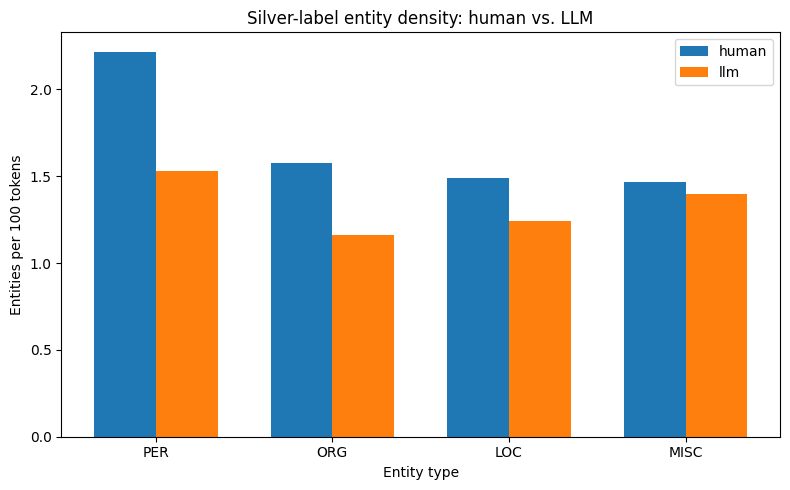

Saved /content/drive/MyDrive/IT469-NER-Project/results/silver/entity_density.png


In [42]:
# entity_density.png: entities per 100 tokens per type, human vs. LLM (aggregated across all 3 real splits).
_density_rows = []
for side in ["human", "llm"]:
    counts = defaultdict(int)
    n_tokens = 0
    for split in ["train", "validation", "test"]:
        records = silver_records[(side, split)]
        n_tokens += sum(len(r["tokens"]) for r in records)
        for _, _, ents in silver_entities[(side, split)]:
            for etype, _ in ents:
                counts[etype] += 1
    for etype in ENTITY_TYPES:
        _density_rows.append({
            "side": side, "entity_type": etype,
            "density": counts.get(etype, 0) / n_tokens * 100 if n_tokens else 0.0,
        })
density_df = pd.DataFrame(_density_rows)

_x = np.arange(len(ENTITY_TYPES))
_width = 0.35
plt.figure(figsize=(8, 5))
for i, side in enumerate(["human", "llm"]):
    _vals = [density_df[(density_df["side"] == side) & (density_df["entity_type"] == t)]["density"].iloc[0] for t in ENTITY_TYPES]
    plt.bar(_x + (i - 0.5) * _width, _vals, width=_width, label=side)
plt.xticks(_x, ENTITY_TYPES)
plt.xlabel("Entity type")
plt.ylabel("Entities per 100 tokens")
plt.title("Silver-label entity density: human vs. LLM")
plt.legend()
plt.tight_layout()
ENTITY_DENSITY_PNG.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ENTITY_DENSITY_PNG, dpi=150)
plt.show()
print(f"Saved {ENTITY_DENSITY_PNG}")


## 9. Entity preservation

For each article, how much of the journalist's entity content also appears (as an exact, lowercased string) in GPT-3.5's version. See Section 0 for the definition and its conservative-lower-bound caveat.


In [43]:
# Gather each article's human-side and LLM-side entity strings (by type) across all of its sentences --
# an article's sentences are all in the same split, so the 6 real files (not the matched duplicate) suffice.
article_entities = defaultdict(lambda: {"human": set(), "llm": set(), "human_by_type": defaultdict(set), "topic": None})
for side, split in SENT_PATHS:
    for aid, topic, ents in silver_entities[(side, split)]:
        for etype, text in ents:
            article_entities[aid][side].add(text.lower())
            if side == "human":
                article_entities[aid]["human_by_type"][etype].add(text.lower())
        article_entities[aid]["topic"] = topic


In [44]:
# Per-article preservation: overall (H = all human entity strings) and per entity type.
by_article_rows = []
n_skipped_empty_h = 0
for aid, data in article_entities.items():
    H, L, topic = data["human"], data["llm"], data["topic"]
    if not H:
        n_skipped_empty_h += 1
        continue
    row = {
        "article_id": aid, "topic": topic,
        "n_human_entity_strings": len(H), "n_preserved": len(H & L),
        "preservation": len(H & L) / len(H),
    }
    for etype in ENTITY_TYPES:
        H_t = data["human_by_type"].get(etype, set())
        row[f"n_human_{etype}"] = len(H_t)
        row[f"preservation_{etype}"] = (len(H_t & L) / len(H_t)) if H_t else np.nan
    by_article_rows.append(row)

entity_preservation_by_article_df = pd.DataFrame(by_article_rows)
entity_preservation_by_article_df.to_csv(ENTITY_PRESERVATION_BY_ARTICLE_CSV, index=False)
logger.info(f"Entity preservation computed for {len(by_article_rows)} articles; "
            f"{n_skipped_empty_h} article(s) skipped (no human entities)")
display(entity_preservation_by_article_df.head(10))


2026-10-16 12:33:45,443 [INFO] Entity preservation computed for 2891 articles; 0 article(s) skipped (no human entities)
INFO:silver_full:Entity preservation computed for 2891 articles; 0 article(s) skipped (no human entities)


,article_id,topic,n_human_entity_strings,n_preserved,preservation,n_human_PER,preservation_PER,n_human_ORG,preservation_ORG,n_human_LOC,preservation_LOC,n_human_MISC,preservation_MISC
0,0,Sports,22,10,0.454545,5,0.400000,4,0.500000,5,0.600000,8,0.375000
1,1,History and religion,41,13,0.317073,8,0.125000,2,0.000000,18,0.277778,13,0.538462
2,2,Politics and government,28,16,0.571429,16,0.687500,6,0.500000,5,0.200000,1,1.000000
3,3,Politics and government,43,20,0.465116,26,0.538462,6,0.166667,9,0.333333,2,1.000000
4,5,Social culture and civil rights,30,9,0.300000,12,0.333333,6,0.166667,8,0.375000,5,0.400000
5,6,Sports,20,6,0.300000,6,0.166667,8,0.125000,5,0.600000,1,1.000000
6,8,Politics and government,20,6,0.300000,12,0.250000,3,0.333333,2,1.000000,3,0.000000
7,9,Politics and government,42,13,0.309524,15,0.266667,9,0.222222,9,0.555556,11,0.363636
8,10,Sports,18,10,0.555556,7,0.714286,4,0.750000,4,0.250000,3,0.333333
9,12,History and religion,25,18,0.720000,5,0.400000,1,0.000000,9,1.000000,10,0.700000


In [45]:
# Summary: mean/median preservation overall, per topic, and per entity type.
summary_rows = [{
    "group_type": "overall", "group": "overall",
    "n_articles": len(entity_preservation_by_article_df),
    "mean_preservation": entity_preservation_by_article_df["preservation"].mean(),
    "median_preservation": entity_preservation_by_article_df["preservation"].median(),
}]

for topic, grp in entity_preservation_by_article_df.groupby("topic"):
    summary_rows.append({
        "group_type": "topic", "group": topic, "n_articles": len(grp),
        "mean_preservation": grp["preservation"].mean(), "median_preservation": grp["preservation"].median(),
    })

for etype in ENTITY_TYPES:
    col = f"preservation_{etype}"
    vals = entity_preservation_by_article_df[col].dropna()
    summary_rows.append({
        "group_type": "entity_type", "group": etype, "n_articles": len(vals),
        "mean_preservation": vals.mean() if len(vals) else np.nan,
        "median_preservation": vals.median() if len(vals) else np.nan,
    })

entity_preservation_summary_df = pd.DataFrame(summary_rows)
entity_preservation_summary_df.to_csv(ENTITY_PRESERVATION_SUMMARY_CSV, index=False)
display(entity_preservation_summary_df)


,group_type,group,n_articles,mean_preservation,median_preservation
0,overall,overall,2891,0.445858,0.437500
1,topic,Celebrity,473,0.436721,0.428571
2,topic,History and religion,482,0.455294,0.445626
3,topic,Politics and government,481,0.467330,0.461538
4,topic,Science and technology,485,0.431892,0.428571
5,topic,Social culture and civil rights,484,0.448384,0.428571
6,topic,Sports,486,0.435563,0.431902
7,entity_type,PER,2862,0.434916,0.428571
8,entity_type,ORG,2858,0.403684,0.400000
9,entity_type,LOC,2768,0.486145,0.500000


## 10. Summary


In [46]:
# One short, final overview of everything this notebook did.
print(f"Selected annotator: {ANNOTATOR_TAG} (validation F1={ANNOTATOR_VAL_F1:.4f})")

if RUN_CODE_CHECK:
    print(f"Code check: F1={code_check_result['code_check_f1']:.4f} vs recorded {code_check_result['recorded_val_f1']:.4f} "
          f"(diff={code_check_result['difference']:.4f}, tolerance {'enforced' if code_check_result['tolerance_enforced'] else 'NOT enforced (smoke test)'})")
else:
    print("Code check: skipped (RUN_CODE_CHECK = False)")

print("\nSentences labeled per file (chunked sentences, BIO repairs):")
display(labeling_summary_df)

print("\nHeadline entity statistics:")
display(entity_stats_df[["side", "split", "n_entities", "entities_per_100_tokens", "pct_sentences_no_entity", "n_distinct_entity_strings"]])

print("\nOverall entity preservation (human -> LLM):")
display(entity_preservation_summary_df[entity_preservation_summary_df["group_type"] == "overall"])

if SMOKE_TEST:
    print("\nSmoke test passed. Set SMOKE_TEST = False and run all cells.")


Selected annotator: roberta-large (validation F1=0.9699)
Code check: F1=0.9699 vs recorded 0.9699 (diff=0.0000, tolerance enforced)

Sentences labeled per file (chunked sentences, BIO repairs):


,side,split,n_sentences,n_tokens,n_chunked,n_bio_repairs
0,human,train,72307,1751319,0,1682
1,human,validation,9060,219427,0,196
2,human,test,9132,217464,0,242
3,llm,train,50521,1342562,0,985
4,llm,validation,6221,168119,0,119
5,llm,test,6265,167623,0,168



Headline entity statistics:


,side,split,n_entities,entities_per_100_tokens,pct_sentences_no_entity,n_distinct_entity_strings
0,human,train,118727,6.779,31.17,28937
1,human,validation,14530,6.622,30.86,5584
2,human,test,14526,6.680,32.30,5828
3,llm,train,71947,5.359,30.80,13807
4,llm,validation,8681,5.164,30.99,2749
5,llm,test,8878,5.296,31.62,2942
6,human,train_matched,91180,6.792,31.16,24429



Overall entity preservation (human -> LLM):


,group_type,group,n_articles,mean_preservation,median_preservation
0,overall,overall,2891,0.445858,0.4375


## 11. References

[1] N. Ayoobi, S. Shahriar, and A. Mukherjee, "Seeing through AI's lens: Enhancing human skepticism
towards LLM-generated fake news," in Proc. 35th ACM Conf. Hypertext and Social Media (HT), 2024.
doi:10.1145/3648188.3675136

[2] E. F. Tjong Kim Sang and F. De Meulder, "Introduction to the CoNLL-2003 shared task:
Language-independent named entity recognition," CoNLL 2003, pp. 142-147. arXiv:cs/0306050

[3] Y. Liu et al., "RoBERTa: A robustly optimized BERT pretraining approach," arXiv:1907.11692, 2019.

[4] J. Devlin, M.-W. Chang, K. Lee, and K. Toutanova, "BERT: Pre-training of deep bidirectional
transformers for language understanding," NAACL-HLT 2019, pp. 4171-4186. doi:10.18653/v1/N19-1423

[5] A. Ushio, L. Neves, V. Silva, F. Barbieri, and J. Camacho-Collados, "Named entity recognition in
Twitter: A dataset and analysis on short-term temporal shifts," AACL-IJCNLP 2022, pp. 309-319.
doi:10.18653/v1/2022.aacl-main.25

[6] D.-H. Lee, "Pseudo-label: The simple and efficient semi-supervised learning method for deep neural
networks," ICML 2013 Workshop on Challenges in Representation Learning.

[7] A. Ratner, S. H. Bach, H. Ehrenberg, J. Fries, S. Wu, and C. Re, "Snorkel: Rapid training data
creation with weak supervision," Proc. VLDB Endowment, vol. 11, no. 3, pp. 269-282, 2017.
doi:10.14778/3157794.3157797

[8] L. A. Ramshaw and M. P. Marcus, "Text chunking using transformation-based learning," in Proc. 3rd
Workshop on Very Large Corpora, 1995. arXiv:cmp-lg/9505040

[9] T. Wolf et al., "Transformers: State-of-the-art natural language processing," in Proc. EMNLP:
System Demonstrations, 2020, pp. 38-45. doi:10.18653/v1/2020.emnlp-demos.6

[10] H. Nakayama, "seqeval: A Python framework for sequence labeling evaluation," 2018.
https://github.com/chakki-works/seqeval
